   # PROJET ACTIFS FINANCIERS 
             Amélie Pires M1 ECAP 2025/2026            

Industries : Telcm et BusSv
# =====================

In [3]:
from pathlib import Path

requirements = Path("code/requirements.txt")

if not requirements.is_file():
    requirements = Path("requirements.txt")

%pip install -r "{requirements}"

  Using cached matplotlib-3.11.2-cp313-cp313-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached scipy-1.18.1-cp313-cp313-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached contourpy-1.4.0-cp313-cp313-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp313-cp313-macosx_11_0_arm64.whl (9.3 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 29.0 MB/s  0:00:00eta 0:00:01
Using cached scipy-1.18.1-cp313-cp313-macosx_14_0_arm64.whl (20.5 MB)
Using cached contourpy-1.4.0-cp313-cp313-macosx_11_0_arm64.whl (285 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 47.0 MB/s  0:00:00
Using cached kiwisolver-1.5.1-cp313-cp313-macosx_11_0_arm64.whl (64 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [4]:
import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm 
import os

In [6]:

# 1. CHARGEMENT DES DONNEES


# Import des fichiers
from pathlib import Path

# Fonctionne depuis la racine du projet ou depuis code/
RACINE_PROJET = Path.cwd()

if not (RACINE_PROJET / "data").is_dir():
    RACINE_PROJET = RACINE_PROJET.parent

DOSSIER_DONNEES = RACINE_PROJET / "data"

# Créer le dossier des figures
DOSSIER_IMAGES = RACINE_PROJET / "figures"
DOSSIER_IMAGES.mkdir(parents=True, exist_ok=True)

# Charger les données
facteurs_brut = pd.read_csv(
    DOSSIER_DONNEES / "FamaFrench_5F.csv"
)

portefeuilles_brut = pd.read_csv(
    DOSSIER_DONNEES / "Portefeuilles_Industries_49.csv"
)

# 1.2 NETTOYAGE

## FACTEURS FAMA-FRENCH 
facteurs = facteurs_brut.copy()
facteurs["Date"] = pd.to_datetime(facteurs["Unnamed: 0"].astype(str), format="%Y%m")
facteurs = facteurs.set_index("Date").sort_index()
facteurs = facteurs.drop(columns=["Unnamed: 0"])
facteurs = facteurs.apply(pd.to_numeric, errors="coerce")

## PORTEFEUILLES INDUSTRIELS
portefeuilles = portefeuilles_brut.copy()
portefeuilles["Date"] = pd.to_datetime(portefeuilles["Unnamed: 0"].astype(str), format="%Y%m")
portefeuilles = portefeuilles.set_index("Date").sort_index()
portefeuilles = portefeuilles.drop(columns=["Unnamed: 0"])
portefeuilles = portefeuilles.apply(pd.to_numeric, errors="coerce")

## ALIGNEMENT DES DATES
dates_communes = facteurs.index.intersection(portefeuilles.index)
facteurs = facteurs.loc[dates_communes]
portefeuilles = portefeuilles.loc[dates_communes]

## Vérifications finales
print("Période étudiée :", dates_communes.min().date(), "→", dates_communes.max().date())
print("Dimensions facteurs :", facteurs.shape)
print("Dimensions portefeuilles :", portefeuilles.shape)
assert "RF" in facteurs.columns, "La colonne RF (taux sans risque) est absente."

Période étudiée : 1963-07-01 → 2025-10-01
Dimensions facteurs : (748, 6)
Dimensions portefeuilles : (748, 49)


In [7]:
# 2. CONSTRUCTION DES VARIABLES

# 2.1 SELECTION DES INDUSTRIES

industries = [
    "Telcm",   
    "BusSv"     
]

rendements_industries = portefeuilles[industries].copy()

print("Industries analysées :", industries)
print("Dimensions rendements industries :", rendements_industries.shape)


# 2.2 RENDEMENTS EXCEDENTAIRES

## Taux sans risque (mensuel)
taux_sans_risque = facteurs["RF"]

## Rendements excédentaires : Ri - Rf
rendements_excedentaires = rendements_industries.sub(taux_sans_risque, axis=0)

## Vérification 
print("Aperçu rendements excédentaires :")
display(rendements_excedentaires.head())


# 2.3 DATASET FINAL DE REGRESSION

## Facteur de marché
facteur_marche = facteurs["Mkt-RF"]

## Facteurs Fama-French 3
facteurs_FF3 = facteurs[["Mkt-RF", "SMB", "HML"]]

## Facteurs Fama-French 5
facteurs_FF5 = facteurs[["Mkt-RF", "SMB", "HML", "RMW", "CMA"]]

## Datasets finis
donnees_CAPM = pd.concat([rendements_excedentaires, facteur_marche], axis=1)
donnees_FF3  = pd.concat([rendements_excedentaires, facteurs_FF3], axis=1)
donnees_FF5  = pd.concat([rendements_excedentaires, facteurs_FF5], axis=1)

print("Dataset CAPM :", donnees_CAPM.shape)
print("Dataset FF3  :", donnees_FF3.shape)
print("Dataset FF5  :", donnees_FF5.shape)

Industries analysées : ['Telcm', 'BusSv']
Dimensions rendements industries : (748, 2)
Aperçu rendements excédentaires :


,Telcm,BusSv
Date,,
1963-07-01,-0.52,-2.27
1963-08-01,4.04,3.34
1963-09-01,2.09,-1.73
1963-10-01,3.14,0.88
1963-11-01,3.87,-2.66


Dataset CAPM : (748, 3)
Dataset FF3  : (748, 5)
Dataset FF5  : (748, 7)


In [8]:
# 3. STATISTIQUES DESCRIPTIVES

## Moyenne et écart-type des rendements excédentaires (mensuels)
statistiques_descriptives = pd.DataFrame({
    "Moyenne (%)": rendements_excedentaires.mean(),
    "Volatilité (%)": rendements_excedentaires.std()
})

print("Statistiques descriptives des rendements excédentaires :")
display(statistiques_descriptives)

## Matrice de corrélation des rendements excédentaires
correlation = rendements_excedentaires.corr()

print("Corrélation entre les industries :")
display(correlation)

Statistiques descriptives des rendements excédentaires :


,Moyenne (%),Volatilité (%)
Telcm,0.444318,4.698526
BusSv,0.617500,5.686936


Corrélation entre les industries :


,Telcm,BusSv
Telcm,1.00000,0.66307
BusSv,0.66307,1.00000


In [9]:
# 4.1 FONCTION REGRESSION OLS

def regression_ols(y, X):
    """
    Régression MCO : y = alpha + beta'X + erreur
    y : Series pandas (rendements excédentaires)
    X : DataFrame pandas (facteurs)
    """
    X = sm.add_constant(X)  # ajoute alpha
    modele = sm.OLS(y, X).fit()
    return modele


# 4.2 REGRESSION CAPM

resultats_CAPM = {}

for industrie in industries:
    y = rendements_excedentaires[industrie]
    X = facteurs[["Mkt-RF"]]
    
    modele = regression_ols(y, X)
    resultats_CAPM[industrie] = modele

    print(f"\n--- CAPM : {industrie} ---")
    print(modele.summary())


# 4.3 REGRESSION FAMA-FRENCH 3 FACTEURS

resultats_FF3 = {}

for industrie in industries:
    y = rendements_excedentaires[industrie]
    X = facteurs[["Mkt-RF", "SMB", "HML"]]
    
    modele = regression_ols(y, X)
    resultats_FF3[industrie] = modele

    print(f"\n--- FF3 : {industrie} ---")
    print(modele.summary())


# 4.4 REGRESSION FAMA-FRENCH 5 FACTEURS

resultats_FF5 = {}

for industrie in industries:
    y = rendements_excedentaires[industrie]
    X = facteurs[["Mkt-RF", "SMB", "HML", "RMW", "CMA"]]
    
    modele = regression_ols(y, X)
    resultats_FF5[industrie] = modele

    print(f"\n--- FF5 : {industrie} ---")
    print(modele.summary())


--- CAPM : Telcm ---
                            OLS Regression Results                            
Dep. Variable:                  Telcm   R-squared:                       0.546
Model:                            OLS   Adj. R-squared:                  0.545
Method:                 Least Squares   F-statistic:                     896.6
Date:                Thu, 05 Nov 2026   Prob (F-statistic):          5.45e-130
Time:                        16:20:04   Log-Likelihood:                -1923.0
No. Observations:                 748   AIC:                             3850.
Df Residuals:                     746   BIC:                             3859.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0195      0.1

Tableau comparatif des modèles :


,Industrie,Modèle,Alpha,p-value alpha,R²
0,Telcm,CAPM,-0.019464,0.867788,0.545838
1,Telcm,FF3,-0.074934,0.514018,0.569894
2,Telcm,FF5,-0.034794,0.763811,0.582046
3,BusSv,CAPM,-0.071506,0.419277,0.822334
4,BusSv,FF3,-0.063041,0.417820,0.865209
5,BusSv,FF5,-0.112558,0.148301,0.871169


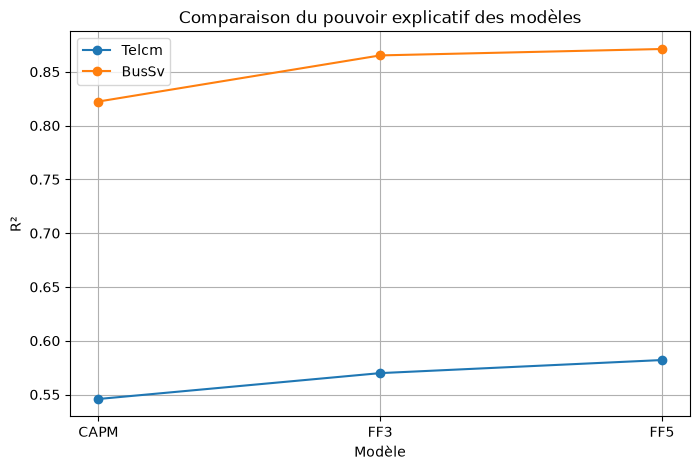

In [10]:
# 5.1 TABLEAU COMPARATIF 

lignes = []

for industrie in industries:
    # CAPM
    lignes.append({
        "Industrie": industrie,
        "Modèle": "CAPM",
        "Alpha": resultats_CAPM[industrie].params["const"],
        "p-value alpha": resultats_CAPM[industrie].pvalues["const"],
        "R²": resultats_CAPM[industrie].rsquared
    })
    
    # FF3
    lignes.append({
        "Industrie": industrie,
        "Modèle": "FF3",
        "Alpha": resultats_FF3[industrie].params["const"],
        "p-value alpha": resultats_FF3[industrie].pvalues["const"],
        "R²": resultats_FF3[industrie].rsquared
    })
    
    # FF5
    lignes.append({
        "Industrie": industrie,
        "Modèle": "FF5",
        "Alpha": resultats_FF5[industrie].params["const"],
        "p-value alpha": resultats_FF5[industrie].pvalues["const"],
        "R²": resultats_FF5[industrie].rsquared
    })

tableau_comparatif = pd.DataFrame(lignes)

print("Tableau comparatif des modèles :")
display(tableau_comparatif)


# 5.2 VISUALISATION : COMPARAISON DES R²

fig, ax = plt.subplots(figsize=(8, 5))

for industrie in industries:
    sous_table = tableau_comparatif[tableau_comparatif["Industrie"] == industrie]
    ax.plot(
        sous_table["Modèle"],
        sous_table["R²"],
        marker="o",
        label=industrie
    )

ax.set_title("Comparaison du pouvoir explicatif des modèles")
ax.set_ylabel("R²")
ax.set_xlabel("Modèle")
ax.legend()
ax.grid(True)

fig.savefig(
    DOSSIER_IMAGES / "comparaison_r2.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

Rolling terminé ✅


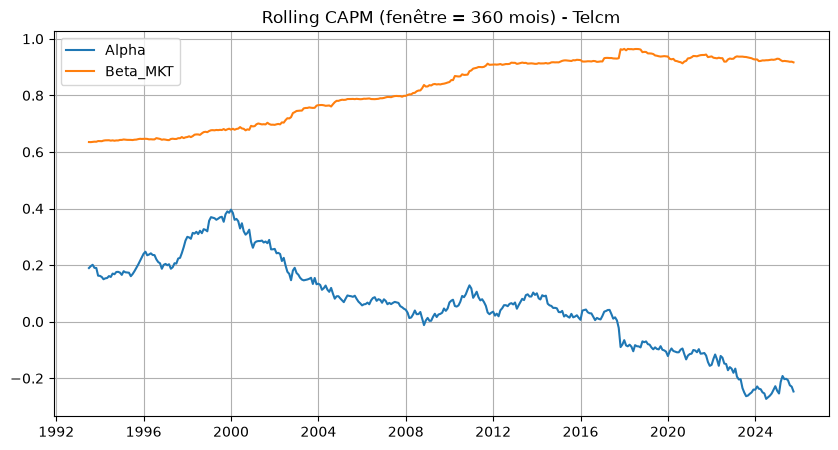

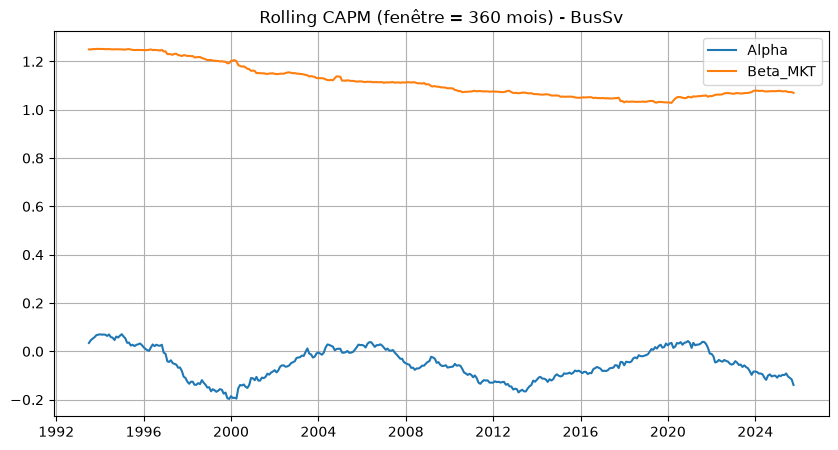

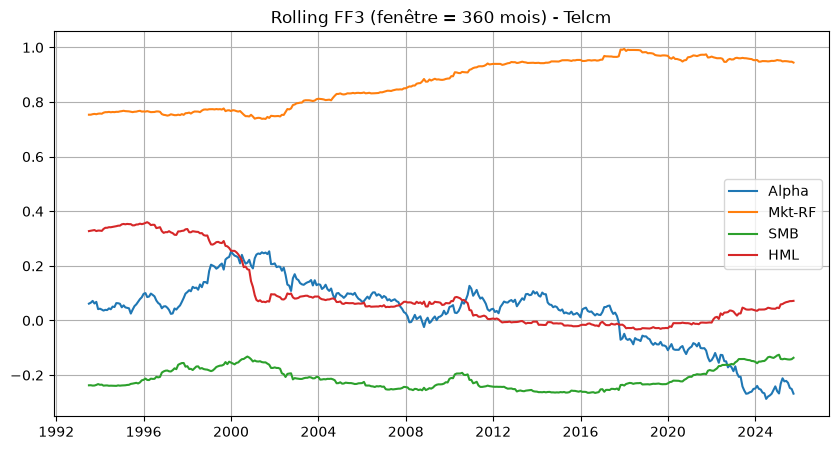

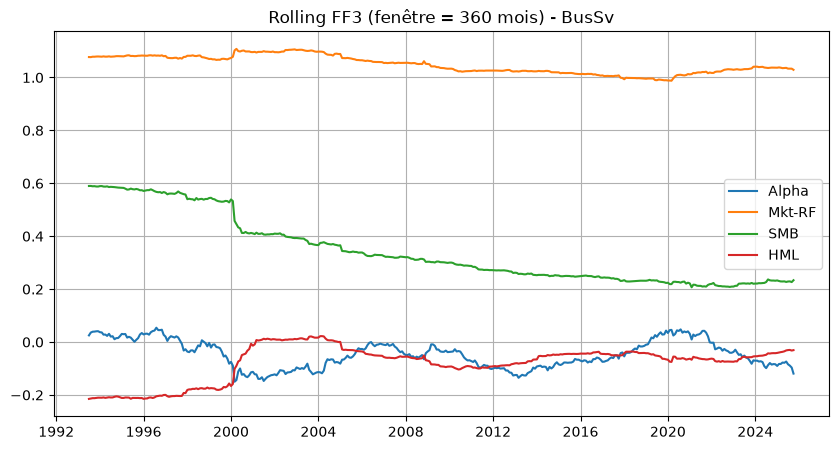

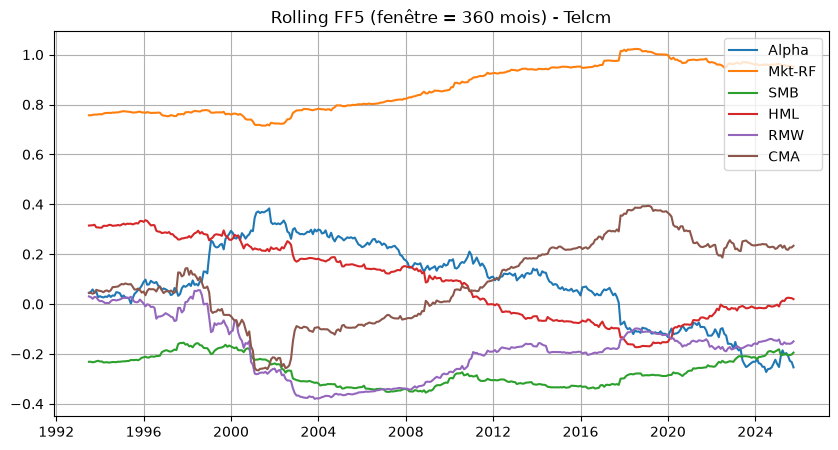

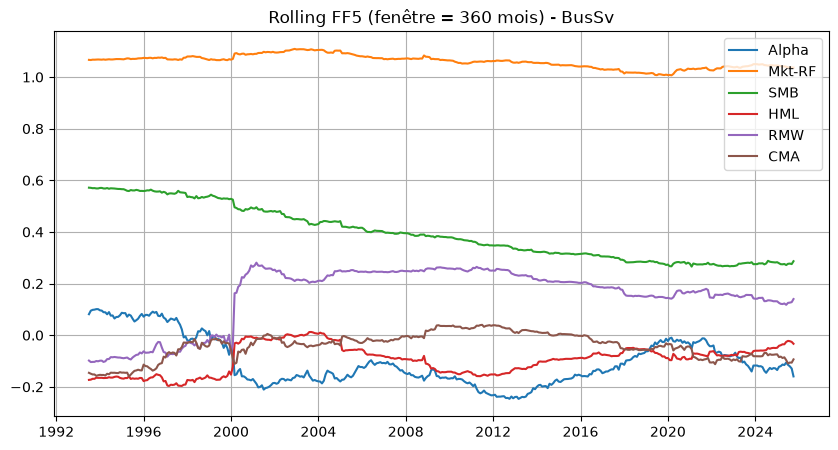

In [11]:
# 6 PARAMETRES ROLLING

FENETRE = 360  # 30 ans (données mensuelles)

# 6.1 FONCTION ROLLING OLS

def rolling_ols(y, X, fenetre=360):
    """
    Estime une régression MCO en rolling window.
    Retourne un DataFrame des coefficients (alpha + betas) indexé par la date.
    
    y : Series (rendement excédentaire)
    X : DataFrame (facteurs)
    fenetre : taille de la fenêtre (en mois)
    """
    data = pd.concat([y, X], axis=1).dropna()  # Alignement et suppression des NA
    y_clean = data.iloc[:, 0]
    X_clean = data.iloc[:, 1:]
    
    dates = data.index
    noms_coeffs = ["Alpha"] + list(X_clean.columns)
    
    coeffs = []
    dates_sortie = []
    
    for t in range(fenetre, len(data)):
        y_w = y_clean.iloc[t-fenetre:t]
        X_w = X_clean.iloc[t-fenetre:t]
        
        X_w = sm.add_constant(X_w)
        modele = sm.OLS(y_w, X_w).fit()
        
        coeffs.append(modele.params.values) # alpha + betas
        dates_sortie.append(dates[t]) # date de fin de fenêtre
    
    coeffs = pd.DataFrame(coeffs, index=dates_sortie, columns=noms_coeffs)
    return coeffs


# 6.2 ROLLING CAPM / FF3 / FF5

## Facteurs par modèles
X_CAPM = facteurs[["Mkt-RF"]]
X_FF3  = facteurs[["Mkt-RF", "SMB", "HML"]]
X_FF5  = facteurs[["Mkt-RF", "SMB", "HML", "RMW", "CMA"]]

## Stockage des résultats rlling
rolling_CAPM = {}
rolling_FF3  = {}
rolling_FF5  = {}

for industrie in industries:
    y = rendements_excedentaires[industrie]
    
    rolling_CAPM[industrie] = rolling_ols(y, X_CAPM, fenetre=FENETRE)
    rolling_FF3[industrie]  = rolling_ols(y, X_FF3,  fenetre=FENETRE)
    rolling_FF5[industrie]  = rolling_ols(y, X_FF5,  fenetre=FENETRE)

print("Rolling terminé ✅")

# ======= GRAPHIQUE : G2 (Rolling CAPM) =======

for industrie in industries:
    df = rolling_CAPM[industrie]
    
    plt.figure(figsize=(10, 5))
    plt.plot(df.index, df["Alpha"], label="Alpha")
    plt.plot(df.index, df["Mkt-RF"], label="Beta_MKT")
    plt.title(f"Rolling CAPM (fenêtre = {FENETRE} mois) - {industrie}")
    plt.grid(True)
    plt.legend()
    plt.show()


# ======= GRAPHIQUE : G3 (Rolling FF3) =======

for industrie in industries:
    df = rolling_FF3[industrie]
    
    plt.figure(figsize=(10, 5))
    for col in df.columns:
        plt.plot(df.index, df[col], label=col)
        
    plt.title(f"Rolling FF3 (fenêtre = {FENETRE} mois) - {industrie}")
    plt.grid(True)
    plt.legend()
    plt.show()


# ======= GRAPHIQUE : G4 (Rolling FF5) =======

for industrie in industries:
    df = rolling_FF5[industrie]
    
    plt.figure(figsize=(10, 5))
    for col in df.columns:
        plt.plot(df.index, df[col], label=col)
        
    plt.title(f"Rolling FF5 (fenêtre = {FENETRE} mois) - {industrie}")
    plt.grid(True)
    plt.legend()
    plt.show()

Alpha statique et tests de significativité :


,Industrie,Modèle,Alpha,t-stat alpha,p-value alpha
0,Telcm,CAPM,-0.019464,-0.166526,0.867788
1,Telcm,FF3,-0.074934,-0.652907,0.514018
2,Telcm,FF5,-0.034794,-0.300591,0.763811
3,BusSv,CAPM,-0.071506,-0.808123,0.419277
4,BusSv,FF3,-0.063041,-0.810660,0.417820
5,BusSv,FF5,-0.112558,-1.447065,0.148301


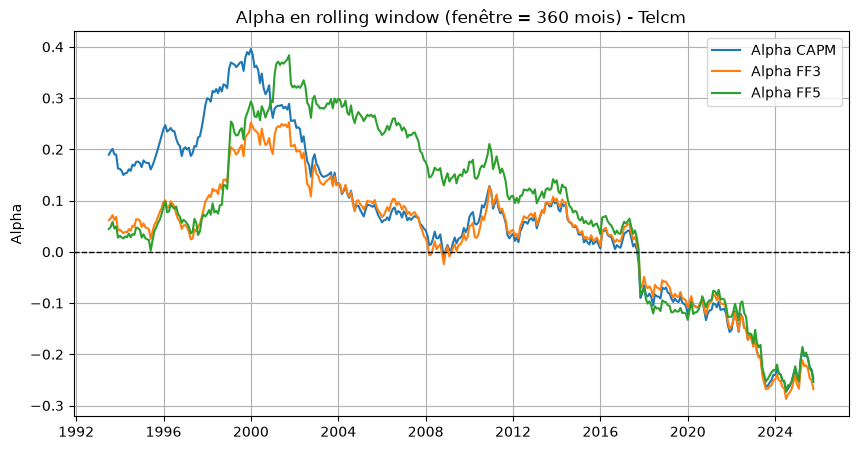

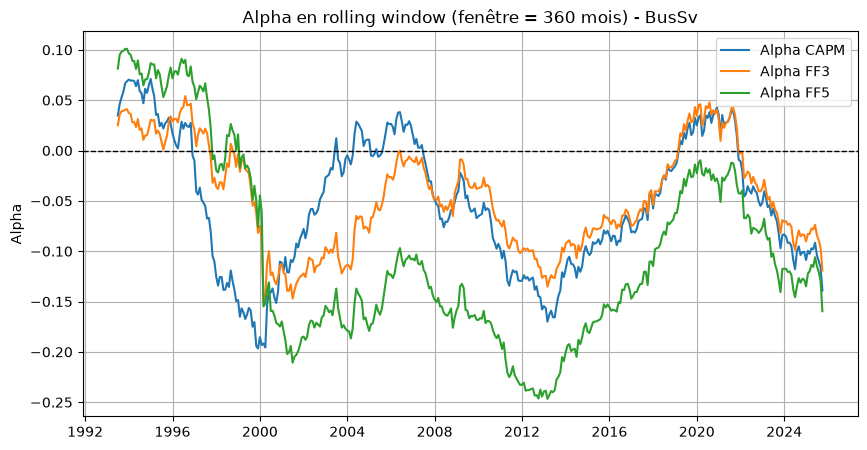

In [12]:
# 7.1 ALPHA STATIQUE + TESTS

lignes_alpha = []

for industrie in industries:
    # CAPM
    lignes_alpha.append({
        "Industrie": industrie,
        "Modèle": "CAPM",
        "Alpha": resultats_CAPM[industrie].params["const"],
        "t-stat alpha": resultats_CAPM[industrie].tvalues["const"],
        "p-value alpha": resultats_CAPM[industrie].pvalues["const"]
    })
    
    # FF3
    lignes_alpha.append({
        "Industrie": industrie,
        "Modèle": "FF3",
        "Alpha": resultats_FF3[industrie].params["const"],
        "t-stat alpha": resultats_FF3[industrie].tvalues["const"],
        "p-value alpha": resultats_FF3[industrie].pvalues["const"]
    })
    
    # FF5
    lignes_alpha.append({
        "Industrie": industrie,
        "Modèle": "FF5",
        "Alpha": resultats_FF5[industrie].params["const"],
        "t-stat alpha": resultats_FF5[industrie].tvalues["const"],
        "p-value alpha": resultats_FF5[industrie].pvalues["const"]
    })

tableau_alpha_statique = pd.DataFrame(lignes_alpha)

print("Alpha statique et tests de significativité :")
display(tableau_alpha_statique)


# 7.2 ALPHA

# ======= GRAPHIQUE : G5 (Rolling alpha) =======

for industrie in industries:
    plt.figure(figsize=(10, 5))
    
    plt.plot(
        rolling_CAPM[industrie].index,
        rolling_CAPM[industrie]["Alpha"],
        label="Alpha CAPM"
    )
    
    plt.plot(
        rolling_FF3[industrie].index,
        rolling_FF3[industrie]["Alpha"],
        label="Alpha FF3"
    )
    
    plt.plot(
        rolling_FF5[industrie].index,
        rolling_FF5[industrie]["Alpha"],
        label="Alpha FF5"
    )
    
    plt.axhline(0, color="black", linestyle="--", linewidth=1)
    plt.title(f"Alpha en rolling window (fenêtre = {FENETRE} mois) - {industrie}")
    plt.ylabel("Alpha")
    plt.grid(True)
    plt.legend()
    plt.savefig(
        DOSSIER_IMAGES / f"alpha_rolling_{industrie.lower()}.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

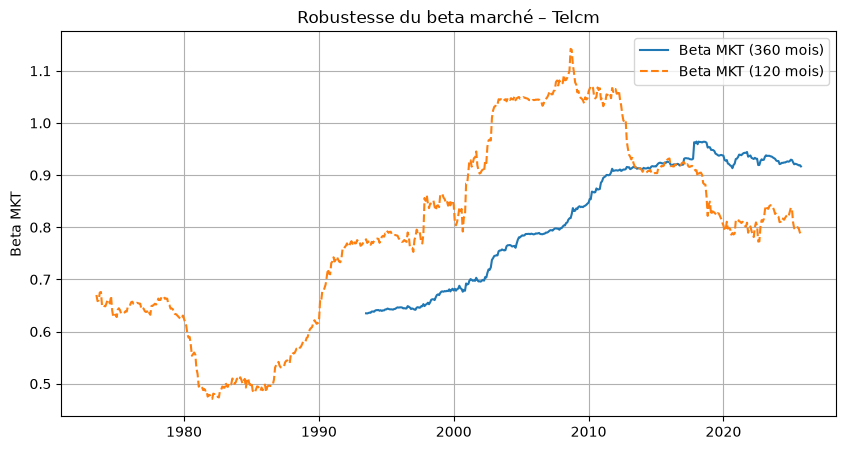

In [13]:
# 8.1 ROBUSTESSE 

FENETRE_COURTE = 120  

rolling_CAPM_120 = {}

for industrie in industries:
    y = rendements_excedentaires[industrie]
    X = facteurs[["Mkt-RF"]]
    rolling_CAPM_120[industrie] = rolling_ols(y, X, fenetre=FENETRE_COURTE)

industrie = "Telcm"  #ou"BusSv"

plt.figure(figsize=(10, 5))
plt.plot(rolling_CAPM[industrie].index,
         rolling_CAPM[industrie]["Mkt-RF"],
         label="Beta MKT (360 mois)")
plt.plot(rolling_CAPM_120[industrie].index,
         rolling_CAPM_120[industrie]["Mkt-RF"],
         label="Beta MKT (120 mois)",
         linestyle="--")

plt.title(f"Robustesse du beta marché – {industrie}")
plt.ylabel("Beta MKT")
plt.legend()
plt.grid(True)
plt.savefig(
    DOSSIER_IMAGES / f"robustesse_beta_{industrie.lower()}.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [14]:
# 8.2 TEST DE CHOW 

from scipy.stats import f

def test_chow(y, X, date_rupture):
    Xc = sm.add_constant(X)
    data = pd.concat([y, Xc], axis=1).dropna()

    data_avant = data.loc[data.index < date_rupture]
    data_apres = data.loc[data.index >= date_rupture]

    y1, X1 = data_avant.iloc[:, 0], data_avant.iloc[:, 1:]
    y2, X2 = data_apres.iloc[:, 0], data_apres.iloc[:, 1:]

    mod_pooled = sm.OLS(data.iloc[:, 0], data.iloc[:, 1:]).fit()
    mod1 = sm.OLS(y1, X1).fit()
    mod2 = sm.OLS(y2, X2).fit()

    RSS_p = mod_pooled.ssr
    RSS_1 = mod1.ssr
    RSS_2 = mod2.ssr

    k = X1.shape[1]  # nb paramètres
    n1, n2 = len(y1), len(y2)

    F_stat = ((RSS_p - (RSS_1 + RSS_2)) / k) / ((RSS_1 + RSS_2) / (n1 + n2 - 2*k))
    p_value = 1 - f.cdf(F_stat, k, n1 + n2 - 2*k)

    return F_stat, p_value


date_crise = "2008-09-01"

F_stat, p_value = test_chow(
    rendements_excedentaires["Telcm"],
    facteurs[["Mkt-RF"]],
    date_crise
)

print("Test de Chow – Telcm (CAPM)")
print("F-stat :", F_stat)
print("p-value :", p_value)

Test de Chow – Telcm (CAPM)
F-stat : 0.9860022966936821
p-value : 0.3735520674457883


In [15]:
# 8.3 ROBUSTESSE DES ERREURS STANDARDS 

industrie = "BusSv"
y = rendements_excedentaires[industrie]
X = facteurs[["Mkt-RF"]]
X = sm.add_constant(X)

modele_robuste = sm.OLS(y, X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 6}
)

print(modele_robuste.summary())

                            OLS Regression Results                            
Dep. Variable:                  BusSv   R-squared:                       0.822
Model:                            OLS   Adj. R-squared:                  0.822
Method:                 Least Squares   F-statistic:                     2068.
Date:                Thu, 05 Nov 2026   Prob (F-statistic):          2.75e-217
Time:                        16:20:13   Log-Likelihood:                -1714.8
No. Observations:                 748   AIC:                             3434.
Df Residuals:                     746   BIC:                             3443.
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0715      0.099     -0.721      0.4

In [16]:
def export_table_pdf(df, filename, fontsize=9, scale=(1, 1.5)):
    """
    Exporte un DataFrame pandas en tableau PDF (pour annexes LaTeX).
    """
    fig, ax = plt.subplots(figsize=(10, 0.6 * len(df) + 1))
    ax.axis("off")
    ax.axis("tight")

    table = ax.table(
        cellText=df.values,
        colLabels=df.columns,
        loc="center"
    )

    table.auto_set_font_size(False)
    table.set_fontsize(fontsize)
    table.scale(scale[0], scale[1])

    plt.savefig(filename, bbox_inches="tight")
    plt.close()

In [17]:
# 9. EXPORT DES TABLEAUX ET FIGURES (POUR MON ANNEXE)

import os
import matplotlib.pyplot as plt

## Dossiers
DOSSIER_TABLEAUX = RACINE_PROJET / "annexes_tableaux"
DOSSIER_FIGURES = RACINE_PROJET / "annexes_figures"

os.makedirs(DOSSIER_TABLEAUX, exist_ok=True)
os.makedirs(DOSSIER_FIGURES, exist_ok=True)


##EXPORTER UN DATAFRAME EN PDF (TABLEAU)
def export_table_pdf(df, filename, fontsize=9, scale=(1, 1.5)):
    """
    Exporte un DataFrame pandas en tableau PDF (pour annexes LaTeX).
    """
    fig, ax = plt.subplots(figsize=(10, 0.6 * len(df) + 1))
    ax.axis("off")
    ax.axis("tight")

    table = ax.table(
        cellText=df.values,
        colLabels=df.columns,
        loc="center"
    )

    table.auto_set_font_size(False)
    table.set_fontsize(fontsize)
    table.scale(scale[0], scale[1])

    plt.savefig(filename, bbox_inches="tight")
    plt.close()


# ======= T1 : Comparaison des modèles (R² + alpha) =======
export_table_pdf(
    tableau_comparatif.round(4),
    f"{DOSSIER_TABLEAUX}/T1.pdf"
)

# ======= T2 : Alpha statique et significativité =======
export_table_pdf(
    tableau_alpha_statique.round(4),
    f"{DOSSIER_TABLEAUX}/T2.pdf"
)

# Sauvegarde CSV 
tableau_comparatif.to_csv(
    f"{DOSSIER_TABLEAUX}/T1_comparaison_modeles.csv",
    index=False
)

tableau_alpha_statique.to_csv(
    f"{DOSSIER_TABLEAUX}/T2_alpha_statique.csv",
    index=False
)


##EXPORT DES GRAPHIQUES STATIQUES

# ======= G1 : Comparaison des R² =======
plt.figure(figsize=(8, 5))

for industrie in industries:
    sous_table = tableau_comparatif[tableau_comparatif["Industrie"] == industrie]
    plt.plot(
        sous_table["Modèle"],
        sous_table["R²"],
        marker="o",
        label=industrie
    )

plt.title("Comparaison du pouvoir explicatif des modèles")
plt.ylabel("R²")
plt.xlabel("Modèle")
plt.legend()
plt.grid(True)

plt.savefig(
    f"{DOSSIER_FIGURES}/G1.pdf",
    bbox_inches="tight"
)
plt.close()


##EXPORT DES GRAPHIQUES ROLLING

# ======= G2 : Rolling CAPM =======
for industrie in industries:
    df = rolling_CAPM[industrie]

    plt.figure(figsize=(10, 5))
    plt.plot(df.index, df["Alpha"], label="Alpha")
    plt.plot(df.index, df["Mkt-RF"], label="Beta_MKT")
    plt.title(f"Rolling CAPM (fenêtre = {FENETRE} mois) - {industrie}")
    plt.grid(True)
    plt.legend()

    plt.savefig(
        f"{DOSSIER_FIGURES}/G2_{industrie}.pdf",
        bbox_inches="tight"
    )
    plt.close()


# ======= G3 : Rolling FF3 =======
for industrie in industries:
    df = rolling_FF3[industrie]

    plt.figure(figsize=(10, 5))
    for col in df.columns:
        plt.plot(df.index, df[col], label=col)

    plt.title(f"Rolling FF3 (fenêtre = {FENETRE} mois) - {industrie}")
    plt.grid(True)
    plt.legend()

    plt.savefig(
        f"{DOSSIER_FIGURES}/G3_{industrie}.pdf",
        bbox_inches="tight"
    )
    plt.close()


# ======= G4 (BONUS) : Rolling FF5 =======
for industrie in industries:
    df = rolling_FF5[industrie]

    plt.figure(figsize=(10, 5))
    for col in df.columns:
        plt.plot(df.index, df[col], label=col)

    plt.title(f"Rolling FF5 (fenêtre = {FENETRE} mois) - {industrie}")
    plt.grid(True)
    plt.legend()

    plt.savefig(
        f"{DOSSIER_FIGURES}/G4_{industrie}.pdf",
        bbox_inches="tight"
    )
    plt.close()


print("Export réssi.")

Export réssi.


In [18]:
# 10. RECAPITULATIF FINAL

print("===== RECAPITULATIF DU PROJET =====\n")

print("Industries analysées :", industries)
print("\n1) Données :")
print("- Rendements mensuels, période longue")
print("- Rendements excédentaires correctement construits (Ri - Rf)")

print("\n2) Modèles estimés :")
print("- CAPM")
print("- Fama-French 3 facteurs")
print("- Fama-French 5 facteurs")

print("\n3) Résultats principaux :")
print("- Le pouvoir explicatif augmente du CAPM vers les modèles multifactoriels")
print("- Les alphas sont non significatifs, quelle que soit l'industrie ou le modèle")
print("- Les expositions aux facteurs sont globalement stables dans le temps")

print("\n4) Analyse dynamique :")
print("- Les rolling windows montrent des variations progressives des betas")
print("- Aucune performance anormale persistante n'est observée")

print("\n5) Tests de robustesse :")
print("- Résultats robustes au choix de la fenêtre rolling")
print("- Absence de rupture structurelle significative (test de Chow)")
print("- Conclusions inchangées avec erreurs standards robustes")

print("\nConclusion :")
print("Les résultats sont cohérents avec la théorie des modèles d'évaluation des actifs\n"
      "et ne mettent pas en évidence de surperformance ajustée du risque.")

===== RECAPITULATIF DU PROJET =====

Industries analysées : ['Telcm', 'BusSv']

1) Données :
- Rendements mensuels, période longue
- Rendements excédentaires correctement construits (Ri - Rf)

2) Modèles estimés :
- CAPM
- Fama-French 3 facteurs
- Fama-French 5 facteurs

3) Résultats principaux :
- Le pouvoir explicatif augmente du CAPM vers les modèles multifactoriels
- Les alphas sont non significatifs, quelle que soit l'industrie ou le modèle
- Les expositions aux facteurs sont globalement stables dans le temps

4) Analyse dynamique :
- Les rolling windows montrent des variations progressives des betas
- Aucune performance anormale persistante n'est observée

5) Tests de robustesse :
- Résultats robustes au choix de la fenêtre rolling
- Absence de rupture structurelle significative (test de Chow)
- Conclusions inchangées avec erreurs standards robustes

Conclusion :
Les résultats sont cohérents avec la théorie des modèles d'évaluation des actifs
et ne mettent pas en évidence de surp